<a href="https://colab.research.google.com/github/taeju1205/Driver_Drowsiness_Detection_CNN/blob/main/DriverDrowsinessDetection_UsingCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Driver Drowsiness Detection using CNN

## Idea
A drowsy driver's eyes stay closed for longer than a normal blink. If we can tell whether an eye image is **open** or **closed**, we can raise an alert when the eyes stay closed for several frames in a row.

## Plan
1. Download the MRL Eye dataset from Kaggle
2. Load the images and label them (Closed = 0, Open = 1)
3. Split into train, validation and test sets
4. Build a small CNN
5. Train for a few epochs
6. Evaluate and test with a simple drowsiness rule

## Step 1: Import Libraries
We use TensorFlow/Keras for the CNN, NumPy for arrays, Matplotlib for plots and scikit-learn for splitting data and metrics.

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Fix seeds so results are repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Download the Dataset
The dataset is downloaded directly from Kaggle using `kagglehub` (no zip file needed).

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imadeddinedjerarda/mrl-eye-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mrl-eye-dataset' dataset.
Path to dataset files: /kaggle/input/mrl-eye-dataset


## Step 3: Collect Image Paths and Labels
We walk through every folder in the dataset. Each image's label comes from the name of the folder it is in: a folder name containing `close` means a closed eye (0), and one containing `open` means an open eye (1).

The full dataset is large, so we take a limited number of images per class to keep training fast.

In [4]:
IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp")
MAX_PER_CLASS = 8000      # images per class (keeps training quick)

closed_paths, open_paths = [], []

for root, dirs, files in os.walk(path):
    folder = os.path.basename(root).lower()
    for f in files:
        if f.lower().endswith(IMG_EXTS):
            full = os.path.join(root, f)
            if "close" in folder:
                closed_paths.append(full)
            elif "open" in folder:
                open_paths.append(full)

print("Closed eye images found:", len(closed_paths))
print("Open eye images found  :", len(open_paths))

# If nothing was found, show the folder structure so we can adjust the code
if len(closed_paths) == 0 or len(open_paths) == 0:
    for root, dirs, files in os.walk(path):
        print(root, "->", len(files), "files")

Closed eye images found: 41946
Open eye images found  : 42952


In [5]:
random.shuffle(closed_paths)
random.shuffle(open_paths)

closed_paths = closed_paths[:MAX_PER_CLASS]
open_paths   = open_paths[:MAX_PER_CLASS]

all_paths  = closed_paths + open_paths
all_labels = [0] * len(closed_paths) + [1] * len(open_paths)   # 0 = Closed, 1 = Open

print("Total images used:", len(all_paths))

Total images used: 16000


## Step 4: Split into Train, Validation and Test
- **Train (70%)**: the model learns from these
- **Validation (15%)**: used to watch progress during training
- **Test (15%)**: used only at the end to check the final performance

In [6]:
train_p, temp_p, train_y, temp_y = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)

val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)

print("Train:", len(train_p), "| Validation:", len(val_p), "| Test:", len(test_p))

Train: 11200 | Validation: 2400 | Test: 2400


## Step 5: Build the Input Pipeline
Each image is:
- read from disk as **grayscale** (eye state does not need colour)
- resized to **64 x 64** pixels
- scaled from 0-255 to 0-1 (helps the network train better)

We use `tf.data` so images are loaded in batches instead of all at once.

In [7]:
IMG_SIZE = 64
BATCH_SIZE = 64

def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_image(img, channels=1, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label

def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_p, train_y, shuffle=True)
val_ds   = make_dataset(val_p, val_y)
test_ds  = make_dataset(test_p, test_y)

## Step 6: Look at Some Images
A quick check that the images and labels make sense.

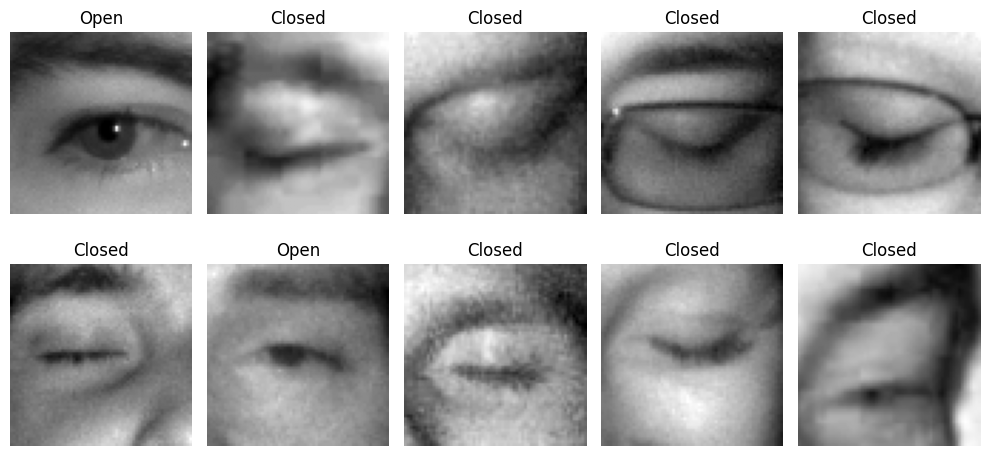

In [8]:
class_names = ["Closed", "Open"]

plt.figure(figsize=(10, 5))
idx = random.sample(range(len(train_p)), 10)
for i, k in enumerate(idx):
    img, label = load_image(train_p[k], train_y[k])
    plt.subplot(2, 5, i + 1)
    plt.imshow(img[:, :, 0], cmap="gray")
    plt.title(class_names[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 7: Build the CNN Model
A CNN learns to find patterns in images. Our model has:

- **Conv2D layers**: small filters that slide over the image and detect edges, shapes and eyelid patterns
- **MaxPooling2D layers**: shrink the image, keeping the important information
- **Flatten**: turns the feature maps into a single list of numbers
- **Dense layers**: make the final decision
- **Dropout**: randomly switches off some neurons during training to reduce overfitting
- **Sigmoid output**: gives a value between 0 and 1. Near 0 means Closed, near 1 means Open

In [9]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 170,881 (667.50 KB)

 Trainable params: 170,881 (667.50 KB)

 Non-trainable params: 0 (0.00 B)

## Step 8: Train the Model
We train for only **5 epochs** (one epoch = one full pass through the training data). This is enough for this dataset and keeps training short.

In [10]:
EPOCHS = 5

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 58s 320ms/step - accuracy: 0.8148 - loss: 0.3929 - val_accuracy: 0.9117 - val_loss: 0.2576
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 70s 256ms/step - accuracy: 0.9157 - loss: 0.2333 - val_accuracy: 0.9312 - val_loss: 0.1756
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 44s 249ms/step - accuracy: 0.9354 - loss: 0.1835 - val_accuracy: 0.9442 - val_loss: 0.1378
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 81s 246ms/step - accuracy: 0.9471 - loss: 0.1512 - val_accuracy: 0.9554 - val_loss: 0.1172
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 85s 264ms/step - accuracy: 0.9533 - loss: 0.1276 - val_accuracy: 0.9658 - val_loss: 0.1010


## Step 9: Training Curves
If training and validation lines stay close together, the model is learning well without memorising the training data.

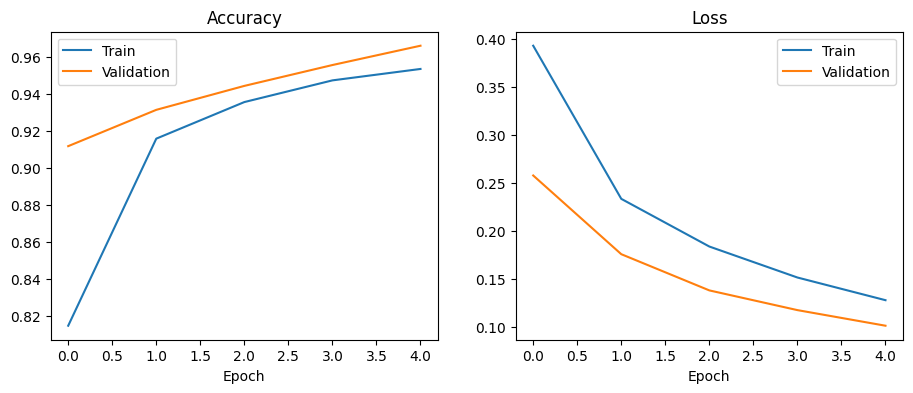

In [11]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

## Step 10: Evaluate on the Test Set
The test set was never seen during training, so it gives an honest measure of performance.

The confusion matrix shows how many images of each class were predicted correctly or wrongly.

Test accuracy: 96.17%

              precision    recall  f1-score   support

      Closed       0.96      0.96      0.96      1200
        Open       0.96      0.96      0.96      1200

    accuracy                           0.96      2400
   macro avg       0.96      0.96      0.96      2400
weighted avg       0.96      0.96      0.96      2400



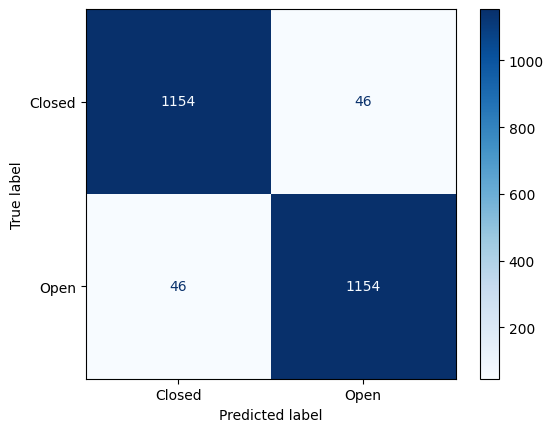

In [12]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc * 100:.2f}%")

# Predictions (probability > 0.5 means Open)
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
y_true = np.array(test_y)

print()
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.show()

## Step 11: Check Some Test Predictions
Green title means the prediction is correct, red means wrong.

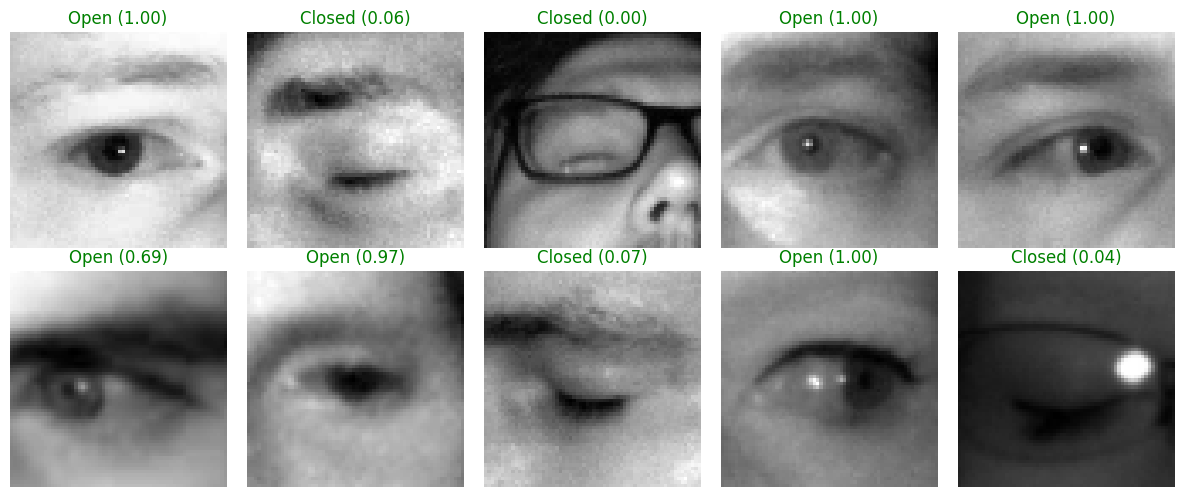

In [13]:
plt.figure(figsize=(12, 5))
idx = random.sample(range(len(test_p)), 10)

for i, k in enumerate(idx):
    img, _ = load_image(test_p[k], test_y[k])
    prob = model.predict(tf.expand_dims(img, 0), verbose=0)[0][0]
    pred = int(prob > 0.5)

    plt.subplot(2, 5, i + 1)
    plt.imshow(img[:, :, 0], cmap="gray")
    plt.title(f"{class_names[pred]} ({prob:.2f})",
              color="green" if pred == test_y[k] else "red")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 12: Turn Eye State into Drowsiness Detection
The CNN only tells us if **one eye image** is open or closed. To detect drowsiness we look at a **sequence of frames** (for example, from a camera):

- A normal blink lasts a fraction of a second, so only 1 or 2 frames show closed eyes
- If the eyes are closed for many frames in a row, the driver is probably drowsy

The function below counts consecutive closed-eye frames and raises an alert when the count reaches a threshold. Here we simulate a video using test images: a few open frames, a short blink, then a long closed period.

In [14]:
CLOSED_FRAME_LIMIT = 5   # alert if eyes are closed for this many frames in a row

def predict_state(file_path):
    img, _ = load_image(file_path, 0)
    prob = model.predict(tf.expand_dims(img, 0), verbose=0)[0][0]
    return "Open" if prob > 0.5 else "Closed"

# Build a fake "video": open frames, a short blink, open frames, then a long eye closure
test_open   = [p for p, y in zip(test_p, test_y) if y == 1]
test_closed = [p for p, y in zip(test_p, test_y) if y == 0]

sequence = (test_open[:3] + test_closed[:2] + test_open[3:6] + test_closed[2:10])

closed_count = 0
for frame_no, frame_path in enumerate(sequence, start=1):
    state = predict_state(frame_path)

    if state == "Closed":
        closed_count += 1
    else:
        closed_count = 0

    alert = "  <-- DROWSINESS ALERT!" if closed_count >= CLOSED_FRAME_LIMIT else ""
    print(f"Frame {frame_no:2d}: {state:6s} | consecutive closed = {closed_count}{alert}")

Frame  1: Closed | consecutive closed = 1
Frame  2: Open   | consecutive closed = 0
Frame  3: Open   | consecutive closed = 0
Frame  4: Closed | consecutive closed = 1
Frame  5: Closed | consecutive closed = 2
Frame  6: Open   | consecutive closed = 0
Frame  7: Open   | consecutive closed = 0
Frame  8: Closed | consecutive closed = 1
Frame  9: Closed | consecutive closed = 2
Frame 10: Open   | consecutive closed = 0
Frame 11: Closed | consecutive closed = 1
Frame 12: Closed | consecutive closed = 2
Frame 13: Closed | consecutive closed = 3
Frame 14: Closed | consecutive closed = 4
Frame 15: Closed | consecutive closed = 5  <-- DROWSINESS ALERT!
Frame 16: Closed | consecutive closed = 6  <-- DROWSINESS ALERT!


## Step 13: Save the Model
The trained model can be saved and later used in a real-time application (for example with OpenCV and a webcam).

In [15]:
model.save("drowsiness_cnn.keras")
print("Model saved as drowsiness_cnn.keras")

Model saved as drowsiness_cnn.keras


## Summary
- We used the MRL Eye dataset to train a small CNN that classifies an eye image as **open** or **closed**.
- The CNN has three convolution + pooling blocks followed by dense layers, trained for only 5 epochs.
- Drowsiness is detected by a simple rule: if the eyes stay closed for several consecutive frames, an alert is raised.

## Possible Improvements
- Use the full dataset and more epochs
- Add data augmentation (rotation, brightness changes)
- Add face and eye detection (OpenCV or MediaPipe) to crop eyes from a live camera feed
- Combine with other signals such as yawning or head position